# Supplementary Fig. 7e: difference between the logarithms of the true and sorted mean firing rates by layer

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel e of Supplementary Fig. 7: as panel d, but the difference between the logarithms of the means is indicated.

**data**: the first 10 minutes of the Kilosort4 sorting (single-units) and of the ground truth of the spontaneous Neuropixels simulation (`dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m`, `dataset/00_raw/ground_truth_npx_spont`). Run time: about 10 seconds.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.validation import true_firing_rate_plots as t

# SETUP PLOT
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 400}
OUT = "figures/8_source_data/supp_fig7e"
os.makedirs(OUT, exist_ok=True)

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Source data

In [2]:
df = t.get_mean_ratio(t.get_firing_rates(), log=True)

In [3]:
display(df.head(8))

,5th,mean,95th
layer,,,
L1,-0.889466,-0.661114,-0.454356
L2/3,-1.427259,-1.339066,-1.225012
L4,-1.483571,-1.280326,-1.130106
L5,-1.161498,-1.022124,-0.867860
L6,-1.482131,-1.340009,-1.187989
pooled,-1.462466,-1.341117,-1.159068


## Plot

In [4]:
def plot_source_data(df):
    """Panel e; the axes have the size of the paper's panel"""
    from src.nodes.validation import supp_fig7_layout as lay

    fig = lay.new_figure(lay.E_CANVAS)
    ax = lay.add_axes_pt(fig, *lay.E_AXES)
    t.plot_mean_ratio(ax, df, log=True)
    ax.set_ylim(*lay.E_YLIM)
    ax.set_xlim(*lay.E_XLIM)
    ax.set_yticks([-1.5, -1.0, -0.5, 0.0], ["\u22121.5", "\u22121.0", "\u22120.5", "0.0"])      # ticks of the paper
    lay.set_text_sizes(fig)
    return fig

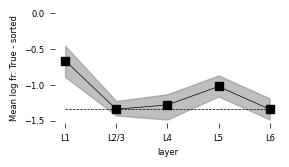

In [5]:
fig = plot_source_data(df)

In [6]:
fig.savefig(f"{OUT}/supp_fig7e.svg", bbox_inches="tight", **savefig_cfg)

## Save source data

In [7]:
df_save = df.reset_index() if df.index.name else df
df_save.to_excel(f"{OUT}/supp_fig7e.xlsx", sheet_name="mean_log_ratio", index=False)

## Replot from the saved source data (the xlsx is sufficient to reproduce the panel)

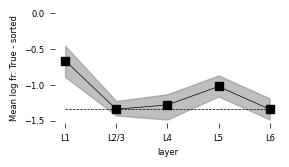

In [8]:
df = pd.read_excel(f"{OUT}/supp_fig7e.xlsx", index_col=0)
fig = plot_source_data(df)